# PathSnap model 02: Gaussian Naive Bayes

*Family: Probabilistic (generative)*

**What every model in this project does.** For each GPS fix we already have a short list of *candidate* road arcs
(all arcs within 50 m, at least 5). Each (fix, candidate) pair is one row with 13 features (distance, heading
difference, …) and a label `y` = 1 if the candidate is the fix's true arc, else 0. The model learns
**P(candidate is the true arc | features)**. For each fix, the candidate with the highest probability is the
prediction. Every model notebook uses the same data, folds and metrics from `pathsnap_common.py`, so the numbers are
directly comparable.

**Metrics used below** (full definitions in the report):
- **Top-1 accuracy** (primary): share of fixes whose highest-probability candidate is the true arc.
- **Macro F1**: per trip, the F1-score of each road arc treated as a class, averaged over arcs (so short, rarely
  visited arcs count as much as long ones), then averaged over trips.
- **Log loss**: how good the probabilities are (lower is better); punishes confident mistakes.
- **Precision / recall / F1 / confusion matrix**: candidate level, "is this the true arc?" with threshold 0.5.
- **Route continuity**: share of consecutive fixes whose predicted arcs are the same or connected within 3 arcs.
- **Route F1**: length-weighted overlap between the set of predicted arcs and the reference route.

## 1. What the algorithm does

**Gaussian Naive Bayes** models each class separately. For "true arc" and for "wrong arc" it fits, for every
feature, a bell curve (Gaussian: a mean and a variance). To score a new row it multiplies the per-feature likelihoods
(the "naive" assumption: features are independent given the class) and applies Bayes' rule:
P(true | x) ∝ P(true) · Π<sub>j</sub> P(x<sub>j</sub> | true).

## 2. Why we tried it for PathSnap, strengths and limitations

- It is a different *kind* of probabilistic model from logistic regression: **generative** (models how features
  are distributed in each class) instead of **discriminative** (models the boundary directly). Comparing the two
  shows whether modelling the class distributions helps.
- **Strengths:** trains in one pass (just means and variances), almost no hyperparameters, trivial to run on all
  1.8 M rows, very fast predictions.
- **Limitations:** our features are strongly correlated (`dist`, `dist_gap` and `nbr_dist` have |ρ| > 0.9), which
  breaks the independence assumption: the same evidence is counted several times, which pushes probabilities to
  0 or 1 (poor calibration, high log loss). Many features are not bell-shaped (`heading_diff` is concentrated near 0
  and 180°, `dist_rank` is an integer), even after the log transform.

### Hyperparameters (initial values) and training objective

| Hyperparameter | Initial value | Meaning |
|---|---|---|
| `var_smoothing` | 1e-9 | small value added to every variance for numerical stability |
| `priors` | from data (≈ 9.6% true arcs) | class frequencies |
| preprocessing | log1p + standardise, one-hot `conn_prev` | log makes the skewed distances more bell-shaped |
| `FRAC` | 1.0 | all reliable-label fixes (training is cheap) |


**Objective:** maximum likelihood. The class means/variances that maximise the likelihood of the training data are
just the sample means/variances, computed in closed form; there is no iterative loss and no training history.

### Setup: load the candidate tables

In [1]:
import sys, time, json
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathsnap_common import *

train = load_partition("train")          # every candidate row of the 80 train trips
test = load_partition("student_test")    # every candidate row of the 10 student_test trips
print(f"train: {len(train):,} rows ({train.keep_train.sum():,} with reliable labels) | student_test: {len(test):,} rows")
print("features:", FEATURES)

train: 2,103,209 rows (1,801,387 with reliable labels) | student_test: 222,004 rows
features: ['dist', 'dist_rank', 'dist_gap', 'heading_diff', 'speed', 'along_t', 'arc_len', 'has_twin', 'junction_deg', 'n_cand20', 'n_cand50', 'nbr_dist', 'conn_prev']


### Model definition

In [2]:
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline

NAME, TITLE, FAMILY = "gaussian_nb", "Gaussian Naive Bayes", "Probabilistic (generative)"
FRAC, SAVE_MODEL = 1.0, True
CONFIG = dict(var_smoothing=1e-9, priors="empirical", preprocessing="log1p+standardise, one-hot conn_prev",
              train_frac=FRAC)


def make_model():
    return make_pipeline(scaled_preprocessor(), GaussianNB(var_smoothing=1e-9))

## 3. Cross-validation (GroupKFold by trip, 5 folds)

The 80 train trips are split into 5 groups of 16. Each fold trains on 64 trips and predicts the 16 held-out trips,
so the model is always scored on trips it has never seen (fixes of one trip are nearly identical, so mixing them
would inflate scores). Training uses a random `FRAC` share of the reliable-label fixes of the 64 trips (all
candidates of a chosen fix stay together); prediction covers every candidate of the held-out trips.
We also score the model on (a sample of) the fixes it was trained on: a large train/validation gap means
**overfitting**; low scores on both mean **underfitting**.

[gaussian_nb] fold 1: train top-1 0.7748 | val top-1 0.7931 | val log loss 0.8294 | fit 3s


[gaussian_nb] fold 2: train top-1 0.7448 | val top-1 0.7728 | val log loss 0.7051 | fit 2s


[gaussian_nb] fold 3: train top-1 0.7674 | val top-1 0.7585 | val log loss 0.8180 | fit 3s


[gaussian_nb] fold 4: train top-1 0.7370 | val top-1 0.7855 | val log loss 0.6604 | fit 3s


[gaussian_nb] fold 5: train top-1 0.7825 | val top-1 0.6990 | val log loss 1.0498 | fit 3s


CV done in 31 s


,fold,train_rows,fit_s,train_top1,val_top1,train_logloss,val_logloss,val_macro_f1,val_precision,val_recall,val_f1,val_continuity,val_route_f1
0,1,1440696,2.9558,0.7748,0.7931,0.7848,0.8294,0.5640,0.5199,0.9307,0.6672,0.9573,0.8128
1,2,1440592,2.4790,0.7448,0.7728,0.8609,0.7051,0.5884,0.5030,0.9001,0.6454,0.9404,0.8258
2,3,1440631,2.8924,0.7674,0.7585,0.8125,0.8180,0.5412,0.4733,0.9030,0.6211,0.9584,0.8058
3,4,1441237,3.2736,0.7370,0.7855,0.8594,0.6604,0.5651,0.5142,0.9117,0.6575,0.9499,0.8123
4,5,1442392,3.3784,0.7825,0.6990,0.7375,1.0498,0.5210,0.4888,0.9266,0.6399,0.9689,0.7767


mean ± std  val top-1 76.18% ± 3.75% | val macro F1 0.5559 ± 0.0257 | val log loss 0.8125


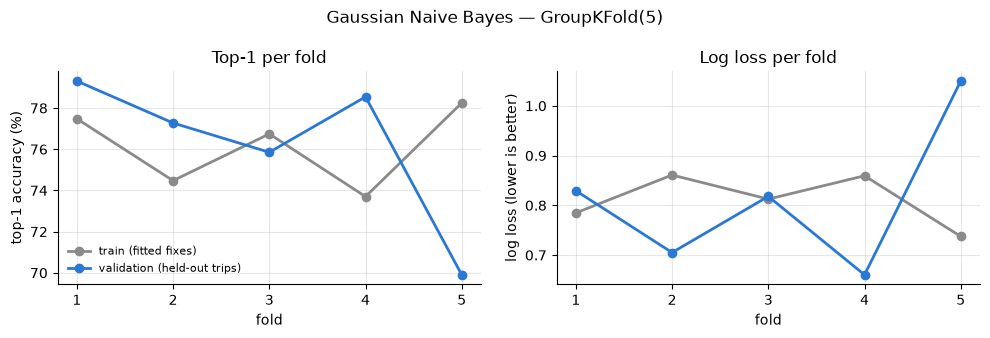

In [3]:
t0 = time.time()
cv, oof, cv_models = run_cv(make_model, train, FRAC, label=NAME)
print(f"CV done in {time.time() - t0:.0f} s")
show = ["fold", "train_rows", "fit_s", "train_top1", "val_top1", "train_logloss", "val_logloss", "val_macro_f1",
        "val_precision", "val_recall", "val_f1", "val_continuity", "val_route_f1"]
display(cv[show].round(4))
print("mean ± std  val top-1 {:.2%} ± {:.2%} | val macro F1 {:.4f} ± {:.4f} | val log loss {:.4f}".format(
    cv.val_top1.mean(), cv.val_top1.std(), cv.val_macro_f1.mean(), cv.val_macro_f1.std(), cv.val_logloss.mean()))
fig = plot_cv(cv, TITLE + " — GroupKFold(5)")
(OUT_DIR / NAME).mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / NAME / "fig_cv.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Final fit on all 80 train trips and evaluation on student_test

Refit with the same recipe on the reliable-label fixes of all 80 train trips, then score every candidate of the 10
student_test trips. student_test is used only for this development-stage comparison, never for training.
**Inference time** is the time `predict_proba` takes for all student_test candidates, per 1 000 GPS fixes
(features are already computed; feature building is the same for every model).

,student_test
top1,0.7820
top1_all,0.7544
macro_f1,0.5732
logloss,0.7279
precision,0.4884
recall,0.9135
f1,0.6365
continuity,0.9667
route_f1,0.8426
fit_s,4.5484


,trip,n_fix,top1,macro_f1,continuity,route_f1
0,00000000,2503,0.9057,0.6073,0.9860,0.8984
1,00000007,1354,0.9532,0.8450,0.9970,0.9332
2,00000009,1049,0.7216,0.5505,0.9618,0.8077
3,00000040,2995,0.8596,0.6603,0.9870,0.8951
4,00000052,262,0.8664,0.6138,0.9502,0.9112
5,00000056,3958,0.7749,0.5738,0.9254,0.8887
6,00000065,768,0.7474,0.5669,0.9478,0.8345
7,00000076,1486,0.7005,0.3902,0.9468,0.7430
8,00000077,3911,0.6255,0.4258,0.9926,0.7039
9,00000091,874,0.7117,0.4980,0.9278,0.8107


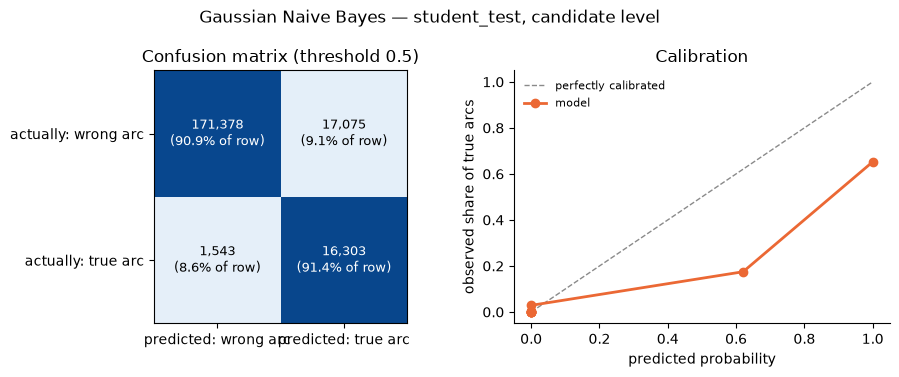

In [4]:
final_model, p_test, test_res, test_preds = fit_and_test(make_model, train, test, FRAC)
keys = ["top1", "top1_all", "macro_f1", "logloss", "precision", "recall", "f1", "continuity", "route_f1",
        "fit_s", "predict_ms_per_1k_fixes"]
display(pd.Series({k: test_res[k] for k in keys}).to_frame("student_test").round(4))
display(pd.DataFrame(test_res["per_trip"]).assign(trip=lambda d: [trips("student_test")[t] for t in d.tidx])
        .assign(top1=lambda d: d.correct_kept / d.n_kept)[["trip", "n_fix", "top1", "macro_f1", "continuity", "route_f1"]].round(4))
fig = plot_confusion_and_calibration(test, p_test, TITLE)
fig.savefig(OUT_DIR / NAME / "fig_confusion_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## Save results

Writes `models_out/<model>/results.json` (config, CV mean/std, student_test metrics), the per-fold table, per-trip student_test table, out-of-fold probabilities (used by the comparison and HMM notebooks) and the fitted model.

In [5]:
summary = save_results(NAME, FAMILY, CONFIG, cv, test_res, model=final_model if SAVE_MODEL else None,
                       oof=oof, p_test=p_test)
print(json.dumps({k: summary[k] for k in ["name", "family", "config"]}, indent=1))
print("saved to", OUT_DIR / NAME)

{
 "name": "gaussian_nb",
 "family": "Probabilistic (generative)",
 "config": {
  "var_smoothing": 1e-09,
  "priors": "empirical",
  "preprocessing": "log1p+standardise, one-hot conn_prev",
  "train_frac": 1.0
 }
}
saved to /home/av8/Documents/ML/Hackathon/models_out/gaussian_nb
